In [284]:
import adabmDCA

import os
import sys
import subprocess
import io
from contextlib import redirect_stdout, redirect_stderr
import importlib
import torch
import numpy as np
import matplotlib.pyplot as plt
import time

from adabmDCA.fasta import get_tokens, import_from_fasta, compute_weights, write_fasta, encode_sequence, decode_sequence
from adabmDCA.stats import get_freq_single_point, get_freq_two_points
from adabmDCA.functional import one_hot
from adabmDCA.utils import init_parameters, init_chains, get_device, get_dtype, get_mask_save
from adabmDCA.sampling import get_sampler, gibbs_sampling
from adabmDCA.training import train_graph
from adabmDCA.statmech import compute_energy

from adabmDCA.io import save_params, save_chains, load_params
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.datasets import make_classification

In [285]:
import RNA
import numpy as np
from Bio import SeqIO
from scipy.stats import pearsonr, spearmanr
import torch
from concurrent.futures import ProcessPoolExecutor
from functools import partial

def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [286]:
import torch

def metropolis(energy_final, energy_initial):
    """
    Vectorized Metropolis acceptance function.
    Args:
        energy_final: (Tensor) Ending state energies, shape [batch_size]
        energy_initial: (Tensor) Starting state energies, shape [batch_size]
    Returns:
        accepted_mask: (Tensor[bool]) Mask of accepted proposals, shape [batch_size]
    """
    delta = energy_final - energy_initial
    prob = torch.exp(-delta)
    rand = torch.rand_like(prob)
    accepted_mask = rand < prob
    return accepted_mask



def hamming_distance_onehot(seq_batch, ref):
    """
    Compute Hamming distance between each sequence in seq_batch and the reference sequence.
    
    Args:
        seq_batch (torch.Tensor): One-hot encoded sequences, shape (N, L, q)
        ref (torch.Tensor): One-hot encoded reference sequence, shape (L, q)
    
    Returns:
        torch.Tensor: Hamming distances, shape (N,)
    """
    # Expand ref to (1, L, q) for broadcasting
    ref_exp = ref.unsqueeze(0)  # (1, L, q)
    
    # Find positions where sequences differ
    diff = (seq_batch != ref_exp).any(dim=-1)  # (N, L), True where differ
    
    # Sum the differences along the sequence length
    hamming = diff.sum(dim=-1)  # (N,)
    
    return hamming

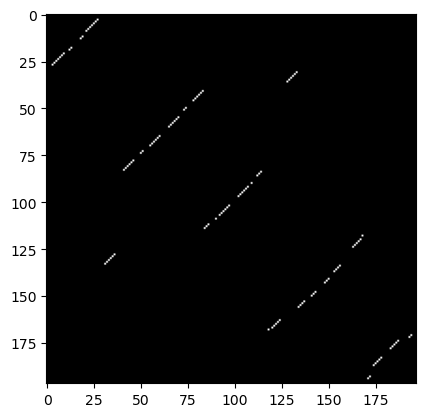

In [287]:
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."


ss_matrix = dot_bracket_to_ss_matrix(dot_bracket_with_pk)

plt.imshow(ss_matrix, cmap='gray')
plt.show()

In [288]:
import pandas as pd

# Load CSV into a pandas DataFrame
csv_path = "Matching_Data.csv"  # Replace with your actual CSV file path
df = pd.read_csv(csv_path)

# Remove duplicate entries based on names (assuming 'sequences' column contains the names)

# Show the first few rows
print(df.head())

                 names  activities_lowT  activities_highT  distances  \
0  dca_f_mutations_129        -1.316208         -2.724580         55   
1  dca_f_mutations_261        -2.664200       -999.000000         60   
2    dca_f_mutations_7        -2.736124       -999.000000         55   
3     dca_f_sequenza_1        -0.048592          1.969441          5   
4    dca_f_sequenza_10         0.261965          1.722767          5   

                                           sequences        DCA        SB  
0  GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...  37.074856  6.852815  
1  GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...  33.076924  4.896689  
2  GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...  28.189787  5.859439  
3  GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...   0.570879  5.453645  
4  GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...  -0.357110  5.515907  


In [289]:
names =  np.array(df['names'])
distances = np.array(df['distances'], float)
activities_lowT = np.array(df['activities_lowT'], float)
activities_highT = np.array(df['activities_highT'], float)
sequences = np.array(df['sequences'])
DCA = np.array(df['DCA'], float)
SB = np.array(df['SB'], float)

In [290]:
SB2 = np.loadtxt('bpp_scores.txt')
DCA2 = np.loadtxt('sequences_en.txt')

In [291]:
params = np.load("modello_FC_T=1")

params_dict = {
    'bias': torch.tensor(params['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

In [292]:
alphabet = "rna"
tokens = 'ACGU-'
path_data = "sequences.fasta"
nat_headers, nat_sequences = import_from_fasta(path_data, tokens=tokens, filter_sequences=False, remove_duplicates=False)
nat_sequences = nat_sequences[:,3:-1]

activities_lowT_min = -2.0

activities_highT_min = -1000
activities_highT_max = -999

distances_min = 25
distances_max = 30

DCA2_min = -1000
DCA2_max = 90

SB2_min = -1000
SB2_max = 25

# Create the mask using min and max for all variables
mask = (activities_highT >= activities_highT_min) & (activities_highT <= activities_highT_max) & \
       (distances >= distances_min) & (distances <= distances_max) & \
       (DCA2 >= DCA2_min) & (DCA2 <= DCA2_max) & \
       (SB2 >= SB2_min) & (SB2 <= SB2_max) & (activities_lowT >= activities_lowT_min)

nat_sequences = nat_sequences[mask]

M, L, q = len(nat_sequences), len(nat_sequences[0]), len(tokens)

print(M, "adjustable sequences")

nat_sequences = torch.from_numpy(nat_sequences)                        # shape (N, L), dtype int32
nat_sequences_one_hot = one_hot(nat_sequences, num_classes=len(tokens))

17 adjustable sequences


In [295]:
wt_index = 0

print(SB2[mask][wt_index], " Matrix Score")
print(DCA2[mask][wt_index], " DCA Score")
print(distances[mask][wt_index], " mutations from azo")
print(activities_lowT[mask][wt_index], "T = 37C actvity")
print(activities_highT[mask][wt_index], "T = 60C actvity")




n_slow_steps = 20
n_fast_sweeps = 10
n_seqs = 100


beta_power = 1
is_power = 2
potential_power = +1


params = params_dict.copy()
params['bias'] = params_dict['bias']*beta_power
params['coupling_matrix'] = params_dict['coupling_matrix']*beta_power
params['bias'] = params['bias'] + nat_sequences_one_hot[wt_index].to("cuda") * is_power 


#chains_0 = torch.randint(low=0, high=len(tokens), size =(n_seqs, L), device="cuda", dtype=torch.int32)
#chains_0 = one_hot(chains_0, num_classes=len(tokens))
chains_0 = nat_sequences_one_hot[wt_index].unsqueeze(0).repeat(n_seqs, 1, 1).to("cuda")

slow_score_0 = torch.tensor(compute_bpp_scores(chains_0, dot_bracket_with_pk,10))

start_time = time.time()

for i in range(n_slow_steps):
    
    chains_1 = gibbs_sampling(chains_0, params, nsweeps=n_fast_sweeps)
    slow_score_1 = torch.tensor(compute_bpp_scores(chains_1, dot_bracket_with_pk, 10))
    accepted_mask = metropolis(-potential_power*slow_score_1, -potential_power*slow_score_0)
    chains_0[accepted_mask] = chains_1[accepted_mask]
    slow_score_0[accepted_mask] = slow_score_1[accepted_mask]
    
    if i == 0:
        elapsed = time.time() - start_time
        estimated_total = elapsed * n_slow_steps
        print(f"Elapsed time for iteration 1: {elapsed:.2f}s")
        print(f"Estimated total time: {estimated_total:.2f}s")
    


24.000059224007884  Matrix Score
77.298416  DCA Score
25.0  mutations from azo
-1.86113850765106 T = 37C actvity
-999.0 T = 60C actvity
Elapsed time for iteration 1: 9.30s
Estimated total time: 185.99s
Elapsed time for iteration 1: 9.30s
Estimated total time: 185.99s


24.000059224007884


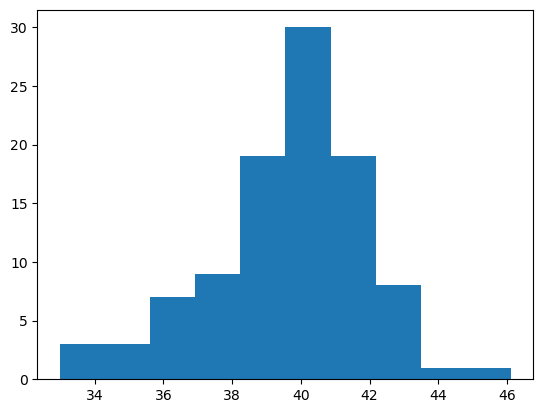

In [296]:
print(SB2[mask][wt_index])

plt.hist(slow_score_0);

77.298416


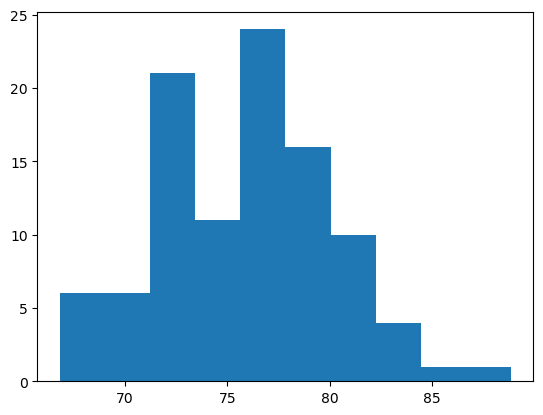

In [297]:
print(DCA2[mask][wt_index])


enes = compute_energy(chains_0, params_dict)
plt.hist(enes.cpu());

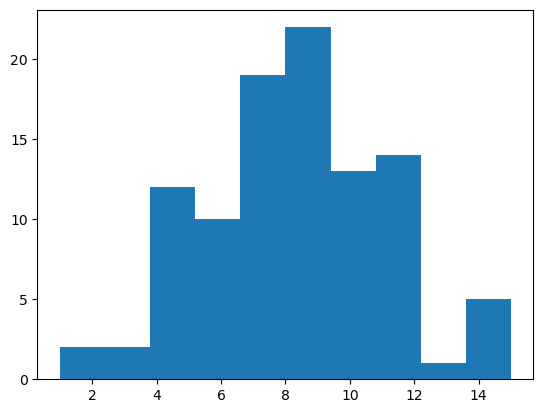

In [298]:
diss =  hamming_distance_onehot(chains_0.cpu(), nat_sequences_one_hot[wt_index].cpu())
plt.hist(diss);

25.0


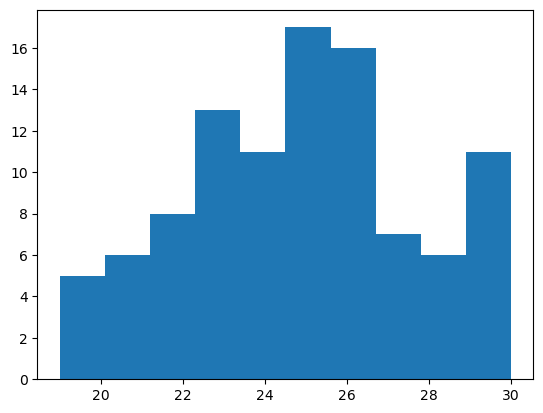

In [299]:
print(distances[mask][wt_index])

path_data = "azo.seq"
azo_header, azo_sequence = import_from_fasta(path_data, tokens=tokens, filter_sequences=False, remove_duplicates=False)
azo_sequence = torch.from_numpy(azo_sequence)                        # shape (N, L), dtype int32
azo_sequence_one_hot = one_hot(azo_sequence, num_classes=len(tokens))
diss_azo =  hamming_distance_onehot(chains_0.cpu(), azo_sequence_one_hot[0].cpu())

plt.hist(diss_azo);

In [306]:
design_energy_th = DCA2[mask][wt_index]

design_lower_SB_th = 38
design_upper_SB_th = 99

design_lower_d = 5
design_upper_d = 10

desing_lower_d_azo = 20
desing_upper_d_azo = 25

# Assuming enes, slow_score_0, diss, diss_azo are defined from previous cells
design_mask = (enes.cpu() < design_energy_th) & (slow_score_0 >= design_lower_SB_th) & (slow_score_0 <= design_upper_SB_th) \
              & (diss >= design_lower_d) & (diss <= design_upper_d) & \
              (diss_azo >= desing_lower_d_azo) & (diss_azo <= desing_upper_d_azo)

In [307]:
sum(design_mask)

tensor(36)

317


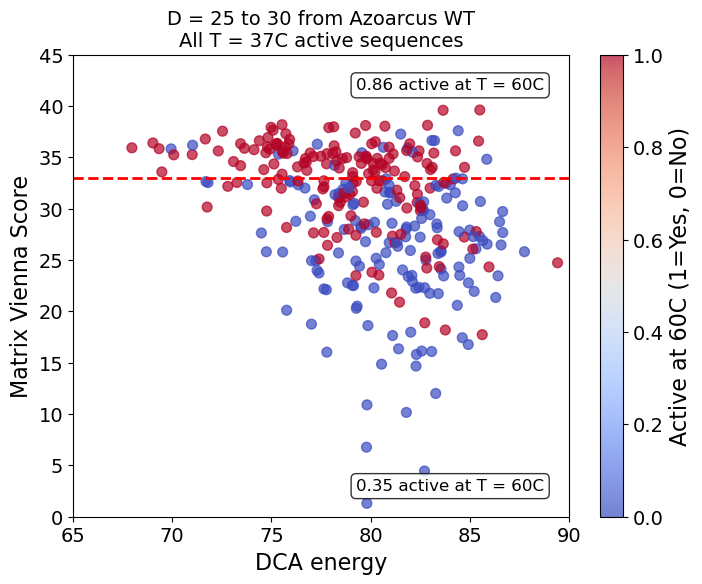

In [308]:
import matplotlib.pyplot as plt
import numpy as np

activities_highT_min = -1000
activities_highT_max = 1000

distances_min = 25
distances_max = 30

DCA2_min = -1000
DCA2_max = 90

SB2_min = -1000
SB2_max = 1000

# Create the mask using min and max for all variables
mask = (activities_highT >= activities_highT_min) & (activities_highT <= activities_highT_max) & \
       (distances >= distances_min) & (distances <= distances_max) & \
       (DCA2 >= DCA2_min) & (DCA2 <= DCA2_max) & \
       (SB2 >= SB2_min) & (SB2 <= SB2_max)

print(sum(mask))
x = DCA2[mask]
y = SB2[mask]

# Choose your threshold for activities_highT
activity_threshold = -2  # Replace with your chosen threshold

# Color based on activities_highT > threshold
colors = (activities_highT[mask] > activity_threshold).astype(int)

# Count above and below the horizontal line (y=33)

SB_activity_th =33
above_line_mask = y > SB_activity_th
below_line_mask = y <= SB_activity_th

# Fractions of color 1 (above activity threshold) above and below the line
if np.sum(above_line_mask) > 0:
    frac_above_color1 = np.mean(colors[above_line_mask])
else:
    frac_above_color1 = 0.0

if np.sum(below_line_mask) > 0:
    frac_below_color1 = np.mean(colors[below_line_mask])
else:
    frac_below_color1 = 0.0

# Create the density plot
fig, ax = plt.subplots(figsize=(8, 6))

# Plot with color based on threshold
sc = ax.scatter(x, y, c=colors, s=50, cmap='coolwarm', alpha=0.7)
ax.set_facecolor('white')
ax.axhline(y=33, color='red', linestyle='--', linewidth=2, label='Threshold at 33')

fig.patch.set_facecolor('white')

# Add labels and title
ax.set_xlabel('DCA energy', fontsize=16)
ax.set_ylabel('Matrix Vienna Score', fontsize=16)
ax.set_title(f'D = {distances_min} to {distances_max} from Azoarcus WT\nAll T = 37C active sequences', fontsize=14)

# Set axis limits
ax.set_xlim([65, 90])
ax.set_ylim([0, 45])

# Increase tick label sizes
ax.tick_params(axis='both', which='major', labelsize=14)

# Add colorbar
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Active at 60C (1=Yes, 0=No)', fontsize=16)
cbar.ax.tick_params(labelsize=14)

# Add text annotations for fractions
ax.text(0.95, 0.95, f'{frac_above_color1:.2f} active at T = 60C', transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right', bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
ax.text(0.95, 0.05, f'{frac_below_color1:.2f} active at T = 60C', transform=ax.transAxes, fontsize=12, verticalalignment='bottom', horizontalalignment='right', bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

plt.show()

In [39]:
import numpy as np

# Assuming you have two vectors: vec1 and vec2 (numpy arrays)
# And thresholds: th1 for vec1, th2 for vec2



activities_highT_min = -1000
activities_highT_max = 1000

distances_min = 25
distances_max = 30

DCA2_min = -1000
DCA2_max = 1000

SB2_min = -1000
SB2_max = 1000

# Create the mask using min and max for all variables
mask = (activities_highT >= activities_highT_min) & (activities_highT <= activities_highT_max) & \
       (distances >= distances_min) & (distances <= distances_max) & \
       (DCA2 >= DCA2_min) & (DCA2 <= DCA2_max) & \
       (SB2 >= SB2_min) & (SB2 <= SB2_max)

print("Filtered sample count:", np.sum(mask))

# Apply the mask



vec1 = SB2[mask]
vec2 = activities_highT[mask]

th1 = 33
th2 = -2

# Predict based on vec1 > th1
predictions = (vec1 >= th1).astype(int)

# True labels based on vec2 > th2
true_labels = (vec2 >= th2).astype(int)

# Confusion matrix
cm = confusion_matrix(true_labels, predictions)
print("Confusion Matrix:")
print(cm)

# Additional metrics-4
accuracy = accuracy_score(true_labels, predictions)
precision = precision_score(true_labels, predictions)
recall = recall_score(true_labels, predictions)
f1 = f1_score(true_labels, predictions)

print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Filtered sample count: 445
Confusion Matrix:
[[223  18]
 [110  94]]
Accuracy: 0.7123595505617978
Precision: 0.8392857142857143
Recall: 0.46078431372549017
F1 Score: 0.5949367088607594


In [38]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Compute raw labels and predictions
predictions = (vec1       >= th1).astype(int)
true_labels = (vec2 >= th2).astype(int)

# Show class counts before balancing
unique, counts = np.unique(true_labels, return_counts=True)
print("Class distribution before balancing:", dict(zip(unique, counts)))

# ---------------------------
# Balance the dataset by undersampling the majority class
idx0 = np.where(true_labels ==-4 0)[0]
idx1 = np.where(true_labels == 1)[0]
n_min = min(len(idx0), len(idx1))

# reproducible sampling
rng = np.random.default_rng(seed=42)
sel0 = rng.choice(idx0, size=n_min, replace=False)
sel1 = rng.choice(idx1, size=n_min, replace=False)
balanced_idx = np.concatenate([sel0, sel1])

# Subset to balanced data
sb_balanced         = vec1[balanced_idx]
activity_balanced   = vec2[balanced_idx]
pred_balanced       = predictions[balanced_idx]
true_balanced       = true_labels[balanced_idx]

# Show class counts after balancing
u2, c2 = np.unique(true_balanced, return_counts=True)
print("Class distribution after balancing:", dict(zip(u2, c2)))

# ---------------------------
# Compute confusion matrix and metrics on balanced data
cm = confusion_matrix(true_balanced, pred_balanced)
print("Balanced Confusion Matrix:")
print(cm)

accuracy  = accuracy_score(true_balanced, pred_balanced)
precision = precision_score(true_balanced, pred_balanced)
recall    = recall_score(true_-4balanced, pred_balanced)
f1        = f1_score(true_balanced, pred_balanced)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")

Class distribution before balancing: {np.int64(0): np.int64(241), np.int64(1): np.int64(204)}
Class distribution after balancing: {np.int64(0): np.int64(204), np.int64(1): np.int64(204)}
Balanced Confusion Matrix:
[[191  13]
 [110  94]]
Accuracy:  0.699
Precision: 0.879
Recall:    0.461
F1 Score:  0.605
